Bank Customer Churn Prediction Assignment

Step 1: Reading the Dataset
--------------------------------------------------
Dataset shape: (10000, 14)

First 5 rows:
   RowNumber  CustomerId   Surname  CreditScore Geography  Gender  Age  \
0          1    15634602  Hargrave          619    France  Female   42   
1          2    15647311      Hill          608     Spain  Female   41   
2          3    15619304      Onio          502    France  Female   42   
3          4    15701354      Boni          699    France  Female   39   
4          5    15737888  Mitchell          850     Spain  Female   43   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0       2       0.00              1          1               1   
1       1   83807.86              1          0               1   
2       8  159660.80              3          1               0   
3       1       0.00              2          0               0   
4       2  125510.82              1          1               

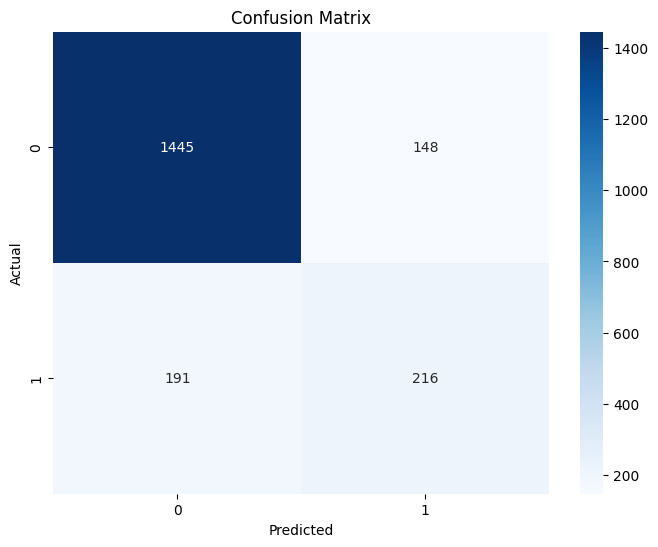

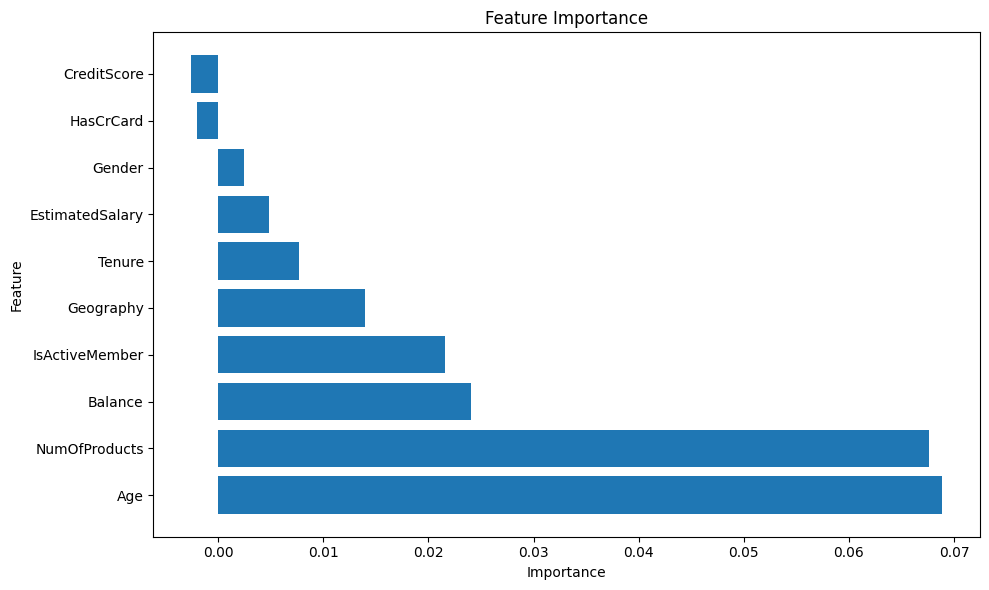

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
print("Bank Customer Churn Prediction Assignment")
print("=" * 50)

# Step 1: Read the dataset
print("\nStep 1: Reading the Dataset")
print("-" * 50)

# Load actual dataset
df = pd.read_csv('Churn_Modelling.csv')

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# Step 2: Distinguish feature and target sets
print("\nStep 2: Distinguishing Feature and Target Sets")
print("-" * 50)

# Drop irrelevant columns
df = df.drop(['RowNumber', 'CustomerId', 'Surname'], axis=1)

# Features (X) and Target (y)
X = df.drop('Exited', axis=1)
y = df['Exited']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

# Step 3: Encode categorical variables
print("\nStep 3: Encoding Categorical Variables")
print("-" * 50)

# Encode categorical columns
label_encoder_geo = LabelEncoder()
label_encoder_gender = LabelEncoder()

X['Geography'] = label_encoder_geo.fit_transform(X['Geography'])
X['Gender'] = label_encoder_gender.fit_transform(X['Gender'])

print("\nEncoded features:")
print(X.head())

# Step 4: Divide into train and test sets
print("\nStep 4: Dividing into Train and Test Sets")
print("-" * 50)

# Split into train and test sets (80-20 split)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)

# Step 5: Normalize the data
print("\nStep 5: Normalizing the Data")
print("-" * 50)

# Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data normalized using StandardScaler")

# Step 6: Initialize and build the model
print("\nStep 6: Initializing and Building the Model")
print("-" * 50)

# Build a Neural Network model (using MLPClassifier)
model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    solver='adam',
    max_iter=500,
    random_state=42
)

print("Model Architecture:")
print(f"Input Layer: {X_train_scaled.shape[1]} neurons")
print(f"Hidden Layer 1: 64 neurons")
print(f"Hidden Layer 2: 32 neurons")
print(f"Output Layer: 1 neuron (binary classification)")

# Train the model
print("\nTraining the model...")
model.fit(X_train_scaled, y_train)
print("Model training completed!")

# Step 7: Evaluate the model
print("\nStep 7: Evaluating the Model")
print("-" * 50)

# Predictions
y_train_pred = model.predict(X_train_scaled)
y_test_pred = model.predict(X_test_scaled)

# Accuracy
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

# Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred)
print("\nConfusion Matrix:")
print(cm)

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.savefig('confusion_matrix.png')
print("\nConfusion matrix saved as 'confusion_matrix.png'")

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_test_pred, target_names=['Not Churned', 'Churned']))

# Step 8: Identify improvements
print("\nStep 8: Identifying Potential Improvements")
print("-" * 50)

improvements = [
    "1. Increase the number of hidden layers or neurons",
    "2. Try different activation functions (tanh, sigmoid)",
    "3. Adjust learning rate",
    "4. Add dropout layers to prevent overfitting",
    "5. Use cross-validation for better model evaluation",
    "6. Perform feature engineering to create new features",
    "7. Handle class imbalance using SMOTE or class weights",
    "8. Try different algorithms (Random Forest, XGBoost, etc.)"
]

for improvement in improvements:
    print(improvement)

# Step 9: Feature importance analysis
print("\nStep 9: Feature Importance Analysis")
print("-" * 50)

# Get feature importance from permutation (simplified approach)
from sklearn.inspection import permutation_importance

result = permutation_importance(model, X_test_scaled, y_test, n_repeats=10, random_state=42)
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': result.importances_mean
})
feature_importance = feature_importance.sort_values('Importance', ascending=False)

print("\nFeature Importance:")
print(feature_importance)

# Plot feature importance
plt.figure(figsize=(10, 6))
plt.barh(feature_importance['Feature'], feature_importance['Importance'])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Feature Importance')
plt.tight_layout()
plt.savefig('feature_importance.png')
print("\nFeature importance plot saved as 'feature_importance.png'")

print("\n" + "=" * 50)
print("Assignment Completed Successfully!")
print("=" * 50)
